# Schlieren and the Foucault knife-edge test

In 1859 Léon Foucault put a razor blade into the image of a pinhole that a
concave telescope mirror formed of itself, and looked past the blade at the
mirror. A perfect sphere went uniformly dark as the blade cut the image; a
mirror with errors showed them as a relief of light and shadow, as if lit
at grazing incidence, with a sensitivity of a few nanometres. Five years
later August Toepler used the same trick on the air itself: in a parallel
beam, the faint index gradients of a hot plume, a shock wave or a gas jet
bend the light by arc seconds, and a knife edge in the focus of the beam
turns these deflections into a picture, the **schlieren** image (German
*Schliere*, a streak in glass). Vasco Ronchi replaced the blade by a coarse
grating in 1923 and got fringes that map the slopes of the mirror.

All of these are **Fourier plane filters**. The focus is the Fourier plane
of the pupil (the mirror or the test section), a ray that leaves the pupil
with the slope $\partial W/\partial x$ crosses it at
$\xi = f\,\partial W/\partial x$, and a filter there decides how bright the
pupil looks to a camera focused on it. It is the 4f system of notebooks
[52](52_abbe_image_formation.ipynb) and
[53](53_phase_contrast_dic.ipynb), seen from the other end.

| Function (`pyoptics.schlieren`) | Purpose |
|---|---|
| `focal_coordinates()` | focal plane coordinates $\xi = f k_x/k$ of the pupil grid |
| `knife_edge()`, `slit()`, `wire()`, `ronchi_ruling()` | the filters |
| `filtered_image()` | coherent image of a point source through a filter |
| `extended_source_image()` | incoherent image of a slit or pinhole source |
| `transverse_aberration()`, `geometric_image()` | the geometric optics limit |
| `knife_edge_contrast()` | Toepler's contrast $\Delta I/I = f\varepsilon/a$ |
| `knife_edge_transfer()` | linear knife-edge image of a weak wavefront at all spatial frequencies |
| `defocus_wavefront()`, `conic_wavefront_at_center()`, `zonal_offset()` | knife position along the axis, a paraboloid at its centre of curvature |
| `air_index()` | refractive index of hot air (Gladstone–Dale) |
| `shadowgraph_contrast()` | the shadowgraph $\Delta I/I = -L\nabla^2 W$ |

Sections:

1. Foucault's test of a perfect sphere: the knife inside, at and outside
   the focus, and the image at the focus as a Hilbert transform,
2. Zernike errors, a raised zone and a turned-down edge in the
   shadowgram, wave optics against the geometric relief picture,
3. the zonal test of a paraboloid: the doughnut, wire and slit, and the
   Couder mask readings against $r^2/R$,
4. Ronchigrams against defocus, compared with the geometric fringe map,
5. how sensitive the knife is: contrast against the wavefront slope and
   the ripple period, the source size, and the famous $\lambda/1000$,
6. schlieren images and shadowgraphs of a hot-air plume above a candle,
   propagated through the index field with the WPM.

Distances are in mm, the wavelength is 550 nm.

In [1]:
import time

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle

from pyoptics import schlieren as sch
from pyoptics import sketch
from pyoptics.bases import fringe_zernike
from pyoptics.propagators import rayleigh_sommerfeld_I_TF
from pyoptics.utils import grid2d, pad
from pyoptics.wpm import wpm_propagate

plt.rcParams.update({"figure.dpi": 80, "font.size": 11, "figure.facecolor": "white",
                     "axes.facecolor": "#fcfcfb", "savefig.facecolor": "white",
                     "axes.spines.top": False, "axes.spines.right": False,
                     "image.origin": "lower"})
BLUE, RED, GREEN, GREY, ORANGE = "#2a7ab9", "#d6604d", "#5aa469", "0.45", "#e0a000"
t_start = time.time()

wl = 0.55e-3                 # mm
k = 2*np.pi/wl
D, R = 150.0, 2400.0         # a 150 mm f/8 mirror, tested at its centre of curvature
N = 512
L = 1.3*D
x, y, X, Y = grid2d(-L/2, L/2, -L/2, L/2, N)
dx = x[1] - x[0]
Rho = np.hypot(X, Y)
A = (Rho <= D/2).astype(float)
rho_n = Rho/(D/2)
xi, eta = sch.focal_coordinates(x, y, wl, R)
extent = (x[0], x[-1], y[0], y[-1])
spot = wl*R/D                # lambda/(2 NA) at the centre of curvature: the size of the pinhole image
print(f"pupil sampling {dx:.2f} mm, focal plane window {xi[-1] - xi[0]:.2f} mm "
      f"sampled at {(xi[1] - xi[0])*1e3:.1f} µm, Airy radius {1.22*spot*1e3:.1f} µm")


def mirror_image(img, ax, title, vmax=None, rim=True, cmap="gray"):
    im = ax.imshow(img, extent=extent, cmap=cmap, vmin=0, vmax=vmax)
    if rim:
        ax.add_patch(Circle((0, 0), D/2, fill=False, color=ORANGE, lw=0.6, ls=":"))
    ax.set_xlim(-0.6*D, 0.6*D); ax.set_ylim(-0.6*D, 0.6*D)
    ax.set_title(title, fontsize=10)
    ax.set_xticks([]); ax.set_yticks([])
    return im


def foucault(W, knife=0.0, a=0.0, n_src=41, mask=None, amplitude=A):
    # image of the mirror with the wavefront error W, knife at `knife` (or another
    # filter), point source (a = 0) or a slit source of half width a
    m = mask if mask is not None else (lambda XI, ETA: sch.knife_edge(XI, ETA, knife))
    field = amplitude*np.exp(1j*k*W)
    if a == 0:
        return np.abs(sch.filtered_image(field, x, y, wl, R, m))**2
    return sch.extended_source_image(field, x, y, wl, R, m, np.linspace(-a, a, n_src))

pupil sampling 0.38 mm, focal plane window 3.46 mm sampled at 6.8 µm, Airy radius 10.7 µm


## 1. Foucault's test of a perfect sphere

The tester sits at the centre of curvature $C$: a pinhole lit by a lamp
just beside $C$, and its image, formed by the mirror, just on the other
side. A knife edge on a stage moves across this image and along the axis.
Behind it the eye (or a camera) is focused on the mirror. Every point of
the mirror sends its light through the focus; a ray from a zone whose
slope is wrong misses it by $\xi = R\,\partial W/\partial x$ and is blocked
or passed by the knife: the zone turns dark or bright.

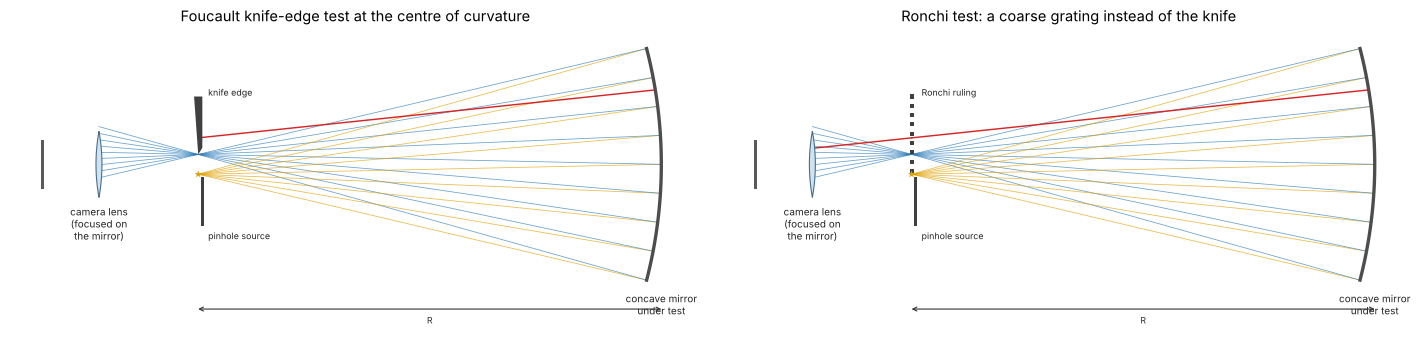

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(18, 5))
sketch.foucault_tester(axes[0], title="Foucault knife-edge test at the centre of curvature")
sketch.foucault_tester(axes[1], test="ronchi", title="Ronchi test: a coarse grating instead of the knife")
plt.tight_layout()

For a perfect sphere all rays meet in the focus. With the knife a little
**inside** the focus (between the mirror and the focus, $\delta < 0$) the
rays have not crossed yet: the knife, coming in from the left, cuts the
rays from the left half of the mirror first, and the shadow sweeps across
the mirror **from the same side** as the knife. **Outside** the focus the
rays have crossed, and the shadow comes from the **opposite** side. At the
focus all of the mirror darkens at once, which is how the test finds the
centre of curvature to a few µm. The pictures below are wave optical, with
a point source, for $\delta = \mp 1$ mm and the knife cutting the axis.

At the focus the knife passes exactly half of the spectrum ($\xi > 0$). In
the image this is the field $\tfrac12\left(U + i\,\mathcal{H}_x U\right)$
with the Hilbert transform $\mathcal{H}_x$ along $x$. For a uniform pupil
row from $x_1$ to $x_2$ it is analytic:

$$I(x) = \frac14\left[\Pi(x) + \frac{1}{\pi^2}\ln^2\left|\frac{x - x_1}{x - x_2}\right|\right],$$

$\Pi = 1$ on the mirror and 0 outside: the mirror goes to a quarter of its
brightness (half the amplitude), its rim lights up in a bright diffraction
ring, and some light appears outside the mirror. The profile on the right
compares a 4× padded simulation of the row $y = 20$ mm with the formula.

largest deviation from the formula more than 8 pixels from the rim: 0.0211


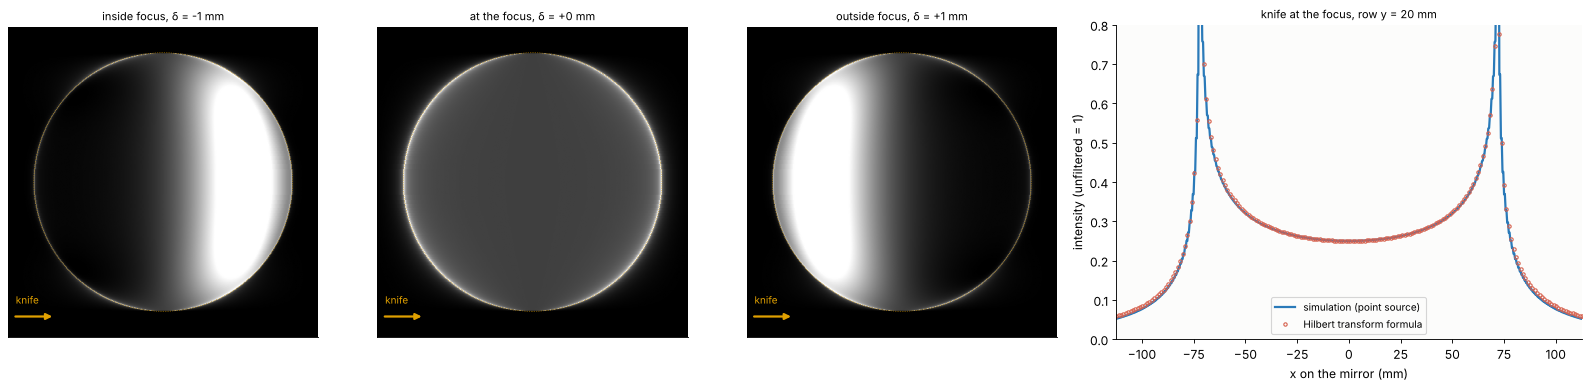

In [3]:
fig, axes = plt.subplots(1, 4, figsize=(20, 5), gridspec_kw=dict(width_ratios=[1, 1, 1, 1.5]))
for ax, d, name in zip(axes, [-1.0, 0.0, 1.0], ["inside focus", "at the focus", "outside focus"]):
    img = foucault(sch.defocus_wavefront(X, Y, R, d))
    mirror_image(img, ax, f"{name}, δ = {d:+.0f} mm", vmax=1.0)
    ax.annotate("", xy=(-0.42*D, -0.52*D), xytext=(-0.58*D, -0.52*D),
                arrowprops=dict(arrowstyle="-|>", color=ORANGE, lw=2))
    ax.text(-0.57*D, -0.47*D, "knife", color=ORANGE, fontsize=9)

Ap, xp, yp = pad(A, x, y, factor=4)
img = np.abs(sch.filtered_image(Ap, xp, yp, wl, R, sch.knife_edge))**2
row = np.argmin(np.abs(yp - 20.0))
cols = np.where(Ap[row] > 0)[0]
x1, x2 = xp[cols[0]] - dx/2, xp[cols[-1]] + dx/2
with np.errstate(divide="ignore"):
    I_h = (np.where((xp > x1) & (xp < x2), 0.25, 0.0)
           + np.log(np.abs((xp - x1)/(xp - x2)))**2/(4*np.pi**2))
ax = axes[3]
ax.plot(xp, img[row], color=BLUE, lw=2, label="simulation (point source)")
ax.plot(xp[::3], I_h[::3], "o", color=RED, ms=3, mfc="none", label="Hilbert transform formula")
ax.set_xlim(-0.75*D, 0.75*D); ax.set_ylim(0, 0.8)
ax.set_xlabel("x on the mirror (mm)"); ax.set_ylabel("intensity (unfiltered = 1)")
ax.set_title("knife at the focus, row y = 20 mm", fontsize=10); ax.legend(fontsize=9)
sel = (np.minimum(np.abs(xp - x1), np.abs(xp - x2)) > 8*dx) & (np.abs(xp) < 0.7*D)
print(f"largest deviation from the formula more than 8 pixels from the rim: "
      f"{np.max(np.abs(img[row][sel] - I_h[sel])):.4f}")
plt.tight_layout()

The simulation follows the formula everywhere except within a few pixels
of the rim, where the logarithm diverges and the sampled pupil edge is a
staircase. In a real test the mirror at the focus looks evenly grey with a
bright rim; the knife on its edge also diffracts, so the rim is usually
brighter on the side opposite the knife when the blade is not exactly at
the centre of the image.

## 2. What errors look like: Zernikes, zones and a turned-down edge

Now the knife stands at the focus and the mirror has errors. In geometric
optics a pupil point is bright when its ray passes the knife,
$R\,\partial W/\partial x > 0$, and dark otherwise. A real pinhole has a
finite image, of half width $a$ in the direction across the knife; when
the knife cuts it in the middle, a point of the mirror is as bright as the
part of the pinhole image that passes:

$$\frac{I}{I_\mathrm{b}} = 1 + \frac{R}{a}\frac{\partial W}{\partial x},
\qquad\text{saturated at 0 and 2,}$$

with the background $I_\mathrm{b}$ of a perfect mirror.

The brightness maps the **slope across the knife**. The eye reads a slope
map as a surface lit from the side, so the mirror looks like a relief of
its errors, lit at grazing incidence from the side **opposite** the knife,
with the height magnified enormously. Below, four Fringe Zernikes of a
quarter wave each (wavefront; the surface error is half of it), with a
slit source of half width $a = 20$ µm (about two Airy radii): the wave
optical image (top) and the geometric one (bottom), both from
`extended_source_image()` (41 source points) and `geometric_image()`
(401 points).

background with the knife at the focus: 0.479 of the unfiltered brightness


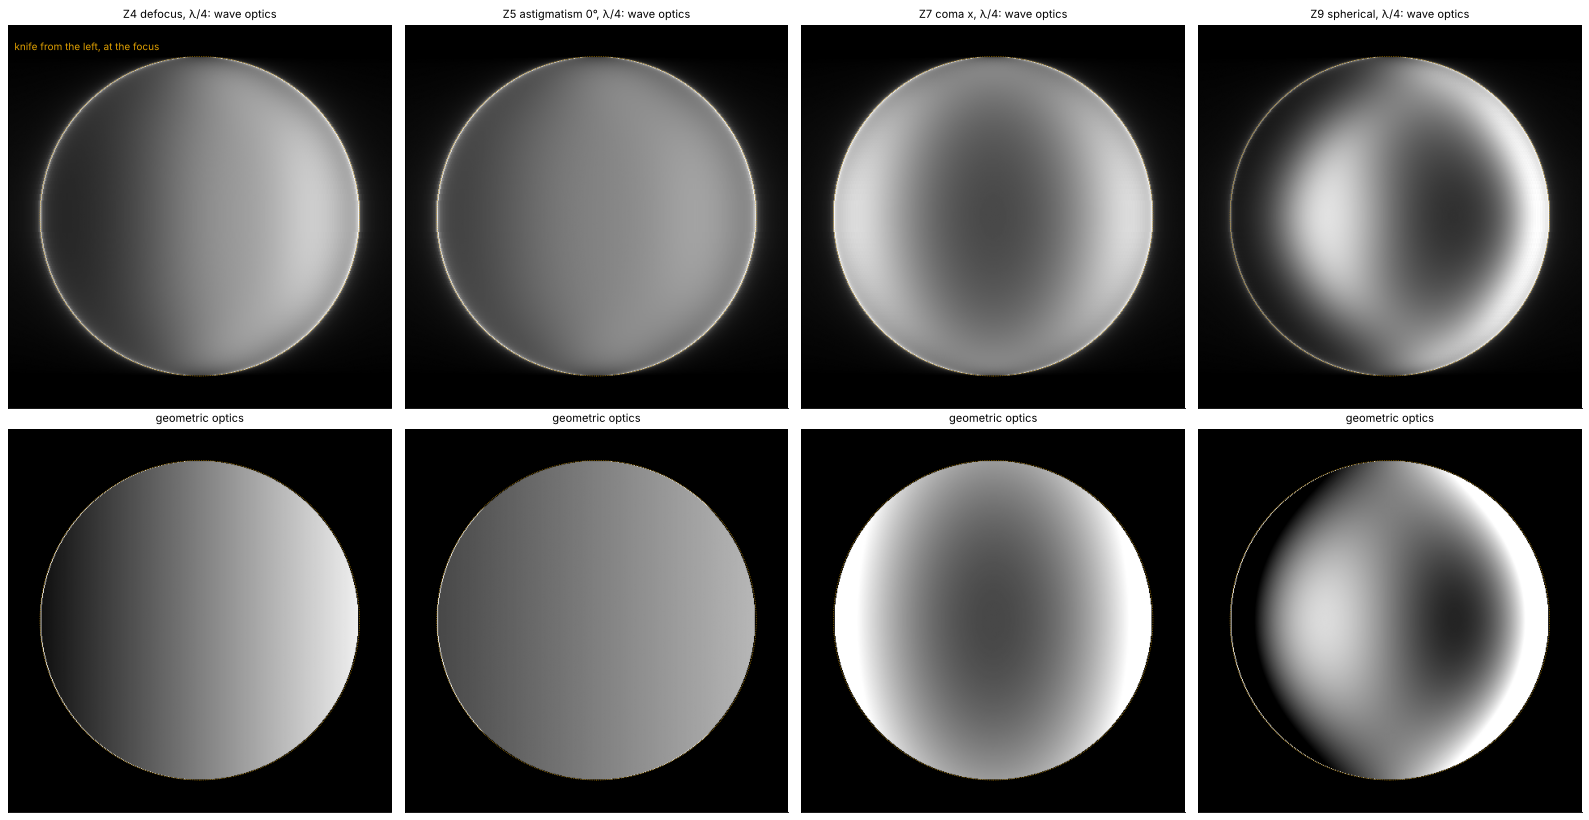

In [4]:
a = 0.02
zern = [(4, "Z4 defocus"), (5, "Z5 astigmatism 0°"), (7, "Z7 coma x"), (9, "Z9 spherical")]
fig, axes = plt.subplots(2, 4, figsize=(20, 10.4))
mask_knife = lambda XI, ETA: sch.knife_edge(XI, ETA)
I_b = foucault(0*X, a=a)[N//2, N//2]       # background: a perfect sphere, knife at the focus
print(f"background with the knife at the focus: {I_b:.3f} of the unfiltered brightness")
for j, (zj, name) in enumerate(zern):
    W = 0.25*wl*fringe_zernike(zj, X/(D/2), Y/(D/2))*A
    img = foucault(W, a=a)
    geo = sch.geometric_image(W, x, y, R, mask_knife, np.linspace(-a, a, 401))*A
    mirror_image(img/I_b, axes[0, j], f"{name}, λ/4: wave optics", vmax=2.0)
    mirror_image(2*geo, axes[1, j], "geometric optics", vmax=2.0)
axes[0, 0].text(-0.58*D, 0.52*D, "knife from the left, at the focus", color=ORANGE, fontsize=9)
plt.tight_layout()

Both agree on the pattern; the wave picture adds the bright rim and
softens the saturated parts. Defocus is the knife off focus (section 1). Astigmatism shows the
classic saddle, coma a lopsided shadow and spherical aberration the
"doughnut" of section 3, where the inner and outer zones focus at
different distances.

Mirror makers fight two smaller errors. A **zone** is a narrow raised or
sunken ring left by the polishing stroke; a **turned-down edge** is a
rounded-off rim, where the pitch lap pressed harder. Both are tiny (here
a zone of 15 nm surface height and 3 mm width at 0.7 of the radius, and
an edge that drops 35 nm over the outer 7 mm), far below a
wavefront tolerance of $\lambda/4$, yet the knife shows them clearly. A
raised surface returns the light earlier, $W = -2h$ for the surface
height $h$.

The profiles along $y = 0$ compare the wave optical shadowgram with two
predictions: the geometric slope formula above (dotted) and the linear
theory of section 5, `knife_edge_transfer()` (dashed), which also
covers structure too fine for geometric optics.

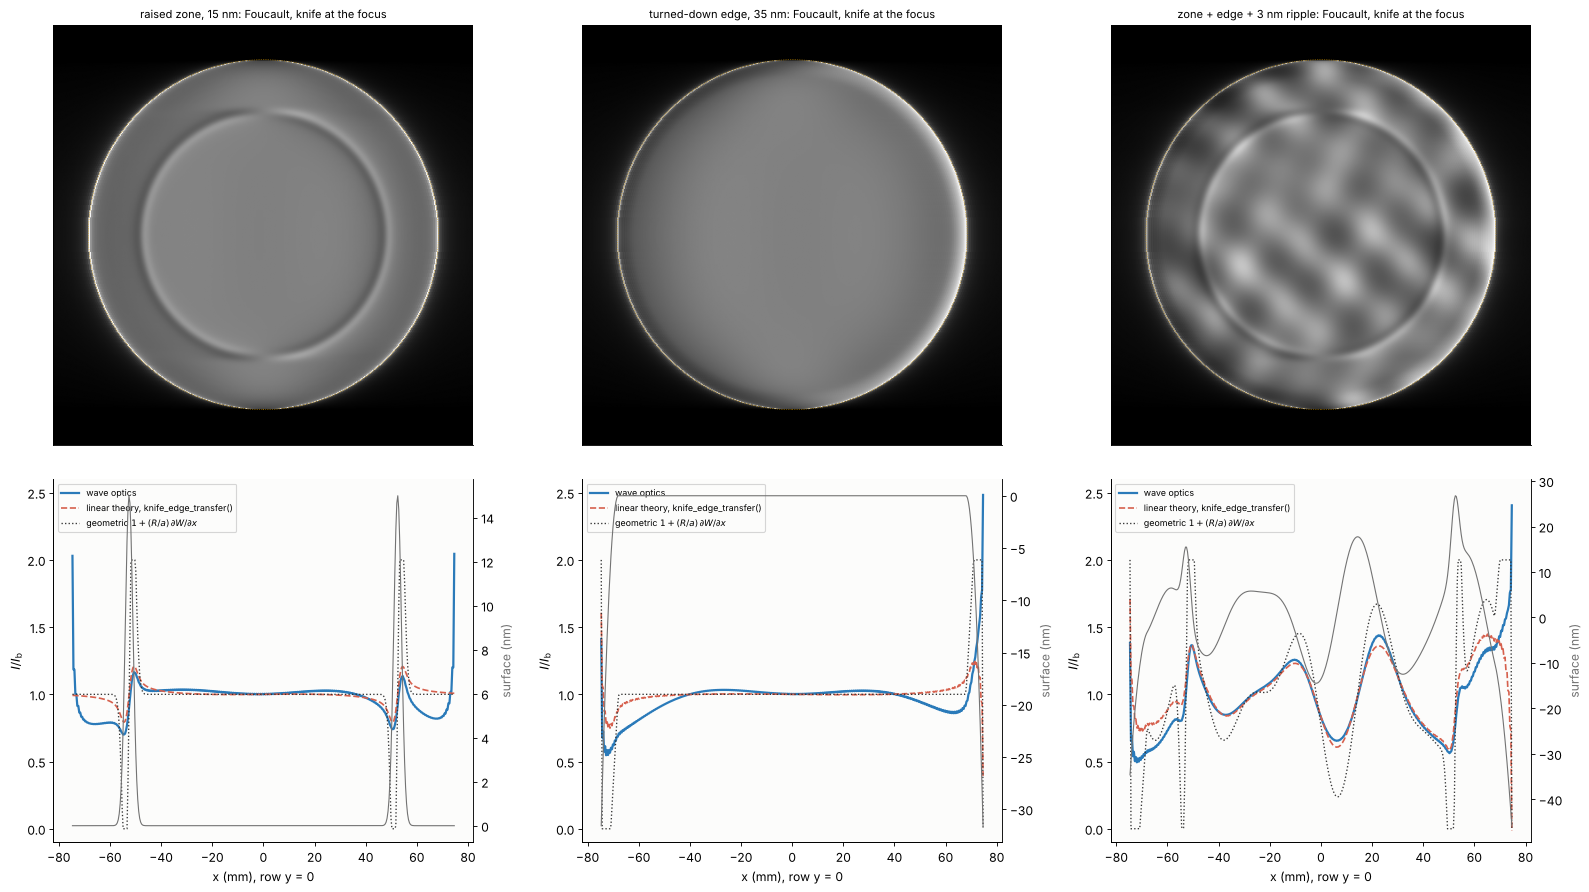

In [5]:
r_mm = Rho
zone = 15e-6*np.exp(-((r_mm - 0.7*D/2)/1.5)**2/2)                       # surface height, mm
edge = -35e-6*np.clip((r_mm - (D/2 - 7))/7, 0, None)**2
rng = np.random.default_rng(7)
ripple = sum(rng.normal()*3e-6*np.cos(2*np.pi*(X*np.cos(th) + Y*np.sin(th))/p + rng.uniform(0, 2*np.pi))
             for th, p in zip(rng.uniform(0, np.pi, 6), rng.uniform(15, 40, 6)))
cases = [("raised zone, 15 nm", zone), ("turned-down edge, 35 nm", edge),
         ("zone + edge + 3 nm ripple", zone + edge + ripple)]
fig, axes = plt.subplots(2, 3, figsize=(20, 11.5), gridspec_kw=dict(height_ratios=[1.25, 1]))
for j, (name, s) in enumerate(cases):
    W = -2*s*A                     # a raised surface shortens the path, twice
    img = foucault(W, a=a)/I_b
    mirror_image(img, axes[0, j], f"{name}: Foucault, knife at the focus", vmax=2.0)
    ax = axes[1, j]
    r0 = N//2
    eps_x, _ = sch.transverse_aberration(W, x, y, 1.0)
    geo = 1 + sch.knife_edge_contrast(eps_x, R, a)
    lin = 1 + sch.knife_edge_transfer(W, x, y, wl, R, a)
    on = np.abs(x) < D/2
    ax.plot(x[on], img[r0, on], color=BLUE, lw=2, label="wave optics")
    ax.plot(x[on], lin[r0, on], "--", color=RED, lw=1.5, label="linear theory, knife_edge_transfer()")
    ax.plot(x[on], geo[r0, on], ":", color="0.2", lw=1.2, label=r"geometric $1 + (R/a)\,\partial W/\partial x$")
    ax2 = ax.twinx()
    ax2.plot(x[on], 1e6*s[r0, on], color=GREY, lw=1)
    ax2.set_ylabel("surface (nm)", color=GREY)
    ax2.spines["right"].set_visible(True)
    ax.set_xlabel("x (mm), row y = 0"); ax.set_ylabel(r"$I/I_\mathrm{b}$"); ax.set_ylim(-0.1, 2.6)
    ax.legend(fontsize=8, loc="upper left")
plt.tight_layout()

With the knife coming from the left, every slope facing right is bright:
the raised zone looks like a ridge lit from the right, and the turned-down
edge like a rim falling away into the light on the right and into shadow
on the left. That is the opticians' rule: the mirror looks like a relief
lit from the side opposite the knife.

The profiles show where geometric optics stops. The zone is 3 mm wide; it
diffracts the light by about $\lambda/3\,\mathrm{mm}$, which lands
$\lambda R/3\,\mathrm{mm} \approx 0.4$ mm from the focus, far outside the
20 µm source image. The knife then no longer measures the slope (the
geometric formula would saturate at 0 and 2) but passes one diffraction
order and blocks the other, and the contrast follows the phase of the zone,
as the linear theory says. The broad turned-down edge and the slow ripple
are in between, and the linear theory follows all of them, apart from a
slow background near the rim, the tail of the rim's diffraction (section
1). The 3 nm
ripple, $\lambda/180$ on the surface, is plainly visible; section 5 works
out why.

## 3. The zonal test of a paraboloid

A telescope mirror is a paraboloid, and at its centre of curvature it is
**not** null: zones at the height $r$ have their centre of curvature at
$R + r^2/(2R)$, and with the source fixed at the paraxial centre their
rays cross the axis $r^2/R$ further out (`zonal_offset()`; for a general
conic $-K r^2/R$). In lowest order the wavefront error is
$W = r^4/(4R^3)$ (`conic_wavefront_at_center()`), here a wave peak to
valley and 2.3 mm of longitudinal aberration. With the knife at the
distance $\delta$ behind the paraxial focus, the zone $r = \sqrt{\delta R}$
is in focus and turns grey; inside it the mirror is dark on one side,
outside on the other: the **doughnut** (dashed: $r = \sqrt{\delta R}$).

paraboloid at the centre of curvature: W = 1.04 waves peak to valley, marginal zone 2.34 mm behind the paraxial focus


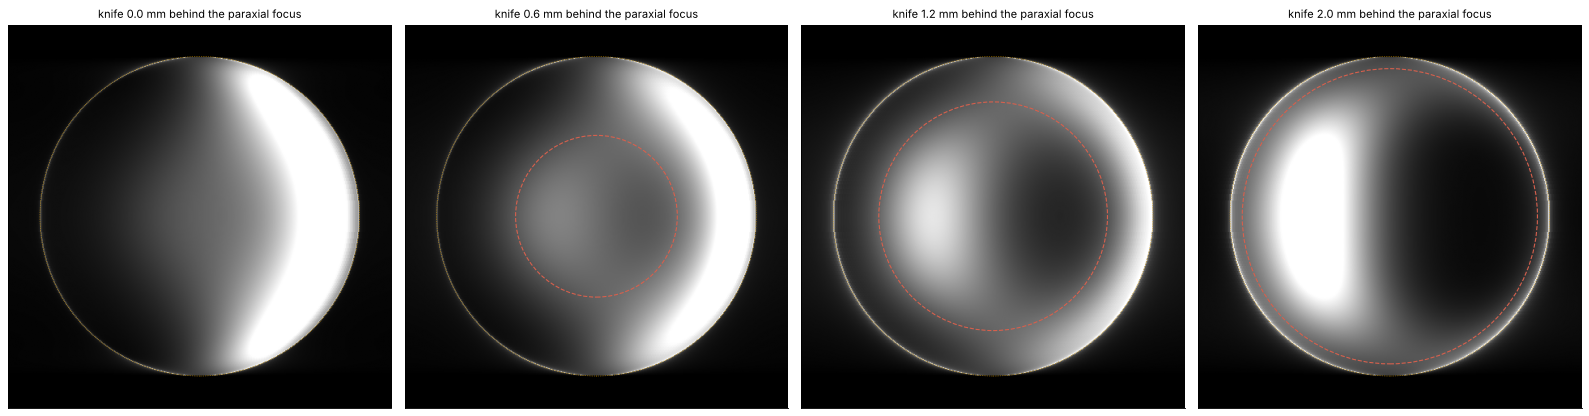

In [6]:
W_par = sch.conic_wavefront_at_center(X, Y, R, -1.0)*A
print(f"paraboloid at the centre of curvature: W = {W_par.max()/wl:.2f} waves peak to valley, "
      f"marginal zone {sch.zonal_offset(D/2, R, -1.0):.2f} mm behind the paraxial focus")
deltas = [0.0, 0.6, 1.2, 2.0]
fig, axes = plt.subplots(1, 4, figsize=(20, 5.2))
for ax, d in zip(axes, deltas):
    img = foucault(W_par + sch.defocus_wavefront(X, Y, R, d), a=0.01)
    mirror_image(img, ax, f"knife {d:.1f} mm behind the paraxial focus", vmax=1.0)
    if 0 < np.sqrt(d*R) < D/2:
        ax.add_patch(Circle((0, 0), np.sqrt(d*R), fill=False, color=RED, lw=1, ls="--"))
plt.tight_layout()

The knife is not the only filter. A thin opaque **wire** across the focus
(the wire test) removes the light of the zones whose rays cross near the
axis, on both sides at once, and shows the zone in focus as a dark ring; a
narrow **slit** passes only that light and shows it as a bright ring on a
dark mirror. For the f/8 mirror the rays of all zones stay within ±36 µm
of the axis, a few diffraction spots, too little for a sharp ring; the
wire test is the tool for fast mirrors. Below a 150 mm **f/4** paraboloid
($R = 1200$ mm, 8 waves of spherical aberration at the centre of
curvature; at the knife position below the rays spread over ±0.16 mm), with all three filters at
$\delta = 2.3$ mm, where the zone $r = \sqrt{\delta R} = 52.5$ mm (0.7 of
the radius) is in focus, a wire and a slit of 60 µm, and a slit source of
20 µm width parallel to them (an incoherent source washes out the coherent
ringing of the sharp filters).

f/4 paraboloid: W = 8.3 waves, rays within ±0.16 mm of the axis at δ = 2.3 mm


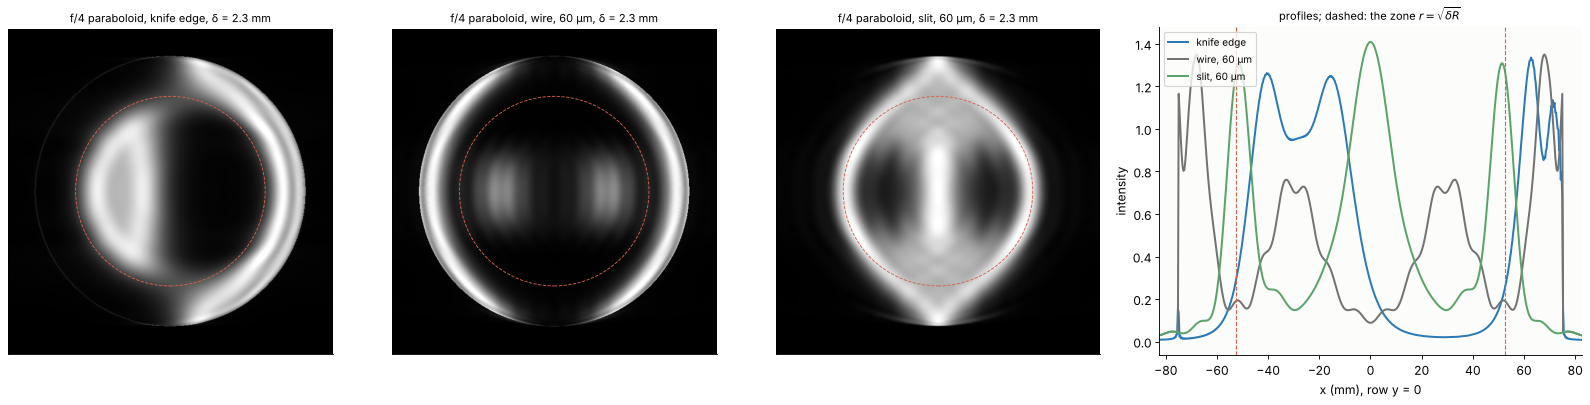

In [7]:
R4 = 1200.0                 # the f/4 mirror, also used for the Ronchi test below
N4 = 640
x4, y4, X4, Y4 = grid2d(-0.65*D, 0.65*D, -0.65*D, 0.65*D, N4)
A4 = (np.hypot(X4, Y4) <= D/2).astype(float)
W_p = sch.conic_wavefront_at_center(X4, Y4, R4, -1.0)
d = 2.3
W_d = (W_p + sch.defocus_wavefront(X4, Y4, R4, d))*A4
print(f"f/4 paraboloid: W = {W_p[A4 > 0].max()/wl:.1f} waves, rays within "
      f"±{np.abs(sch.transverse_aberration(W_d, x4, y4, R4)[0][A4 > 0]).max():.2f} mm of the axis at δ = {d} mm")
filters = [("knife edge", lambda XI, ETA: sch.knife_edge(XI, ETA)),
           ("wire, 60 µm", lambda XI, ETA: sch.wire(XI, ETA, 0.06)),
           ("slit, 60 µm", lambda XI, ETA: sch.slit(XI, ETA, 0.06))]
fig, axes = plt.subplots(1, 4, figsize=(20, 5.2), gridspec_kw=dict(width_ratios=[1, 1, 1, 1.3]))
rows = {}
for ax, (name, m) in zip(axes, filters):
    img = sch.extended_source_image(A4*np.exp(1j*k*W_d), x4, y4, wl, R4, m, np.linspace(-0.01, 0.01, 21))
    rows[name] = img[N4//2]
    ax.imshow(img, extent=(x4[0], x4[-1], y4[0], y4[-1]), cmap="gray", vmin=0,
              vmax=np.percentile(img[A4 > 0], 99.5))
    ax.set_xlim(-0.6*D, 0.6*D); ax.set_ylim(-0.6*D, 0.6*D); ax.set_xticks([]); ax.set_yticks([])
    ax.set_title(f"f/4 paraboloid, {name}, δ = {d} mm", fontsize=10)
    ax.add_patch(Circle((0, 0), np.sqrt(d*R4), fill=False, color=RED, lw=0.8, ls="--"))
ax = axes[3]
for (name, r_), c in zip(rows.items(), [BLUE, GREY, GREEN]):
    ax.plot(x4, r_, color=c, lw=1.8, label=name)
for s in (-1, 1):
    ax.axvline(s*np.sqrt(d*R4), color=RED, ls="--", lw=1)
ax.set_xlim(-0.55*D, 0.55*D); ax.set_xlabel("x (mm), row y = 0"); ax.set_ylabel("intensity")
ax.legend(fontsize=9); ax.set_title("profiles; dashed: the zone $r = \\sqrt{\\delta R}$", fontsize=10)
plt.tight_layout()

The wire darkens the zone in focus on both sides, and also the vertical
band through the centre, where $\partial W/\partial x$ vanishes for every
zone: like the knife, the wire only sees slopes across it. The slit shows
the complement, but blurred: it is a low-pass filter, and an image formed
through a slit of width $w$ cannot resolve details finer than
$\lambda R/w$ (11 mm here) across it. The knife passes a half plane and
keeps the full resolution, one reason why it remained the standard.

To measure the mirror, the optician puts a **Couder mask** on it: a screen
with pairs of windows over a few zones. For each zone the knife is moved
along the axis until the two windows of the pair, left and right, are
equally grey; the stage reading is the zone's focus. The simulation does
the same for six zones (windows 8 mm wide in radius and ±30° in azimuth),
with the pupil reduced to the two windows, and finds the knife position where the left and right
brightness cross. A tester whose source moves with the knife (common in
amateur practice) sees the beam refocus twice as fast and reads
$r^2/(2R)$. A fit of $\delta = -K r^2/R$ to the readings returns the conic
constant.

fixed source: largest deviation from the formula 8 µm, fitted conic constant K = -1.005
moving source: largest deviation from the formula 4 µm, fitted conic constant K = -1.005


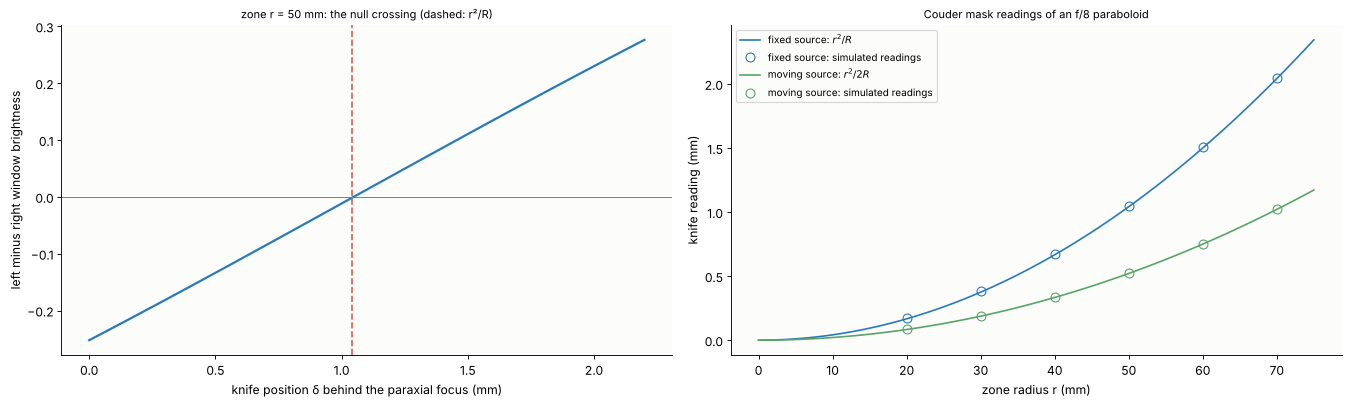

In [8]:
zones = np.array([20.0, 30.0, 40.0, 50.0, 60.0, 70.0])
d_scan = np.linspace(0.0, 2.2, 45)


def couder_reading(rz, moving_source=False):
    win = ((np.abs(Rho - rz) < 4) & (np.abs(Y) < np.abs(X)*np.tan(np.pi/6)) & (A > 0)).astype(float)
    diff = []
    for d in d_scan:
        img = foucault(W_par + sch.defocus_wavefront(X, Y, R, (2 if moving_source else 1)*d),
                       amplitude=win)
        diff.append(img[(win > 0) & (X < 0)].mean() - img[(win > 0) & (X > 0)].mean())
    diff = np.array(diff)
    j = np.where(np.sign(diff[:-1]) != np.sign(diff[1:]))[0][0]
    return d_scan[j] - diff[j]*(d_scan[j + 1] - d_scan[j])/(diff[j + 1] - diff[j]), diff


readings = {ms: np.array([couder_reading(rz, ms)[0] for rz in zones]) for ms in (False, True)}
fig, axes = plt.subplots(1, 2, figsize=(17, 5.2))
ax = axes[0]
_, diff = couder_reading(50.0)
ax.plot(d_scan, diff, color=BLUE, lw=2)
ax.axhline(0, color=GREY, lw=0.8); ax.axvline(sch.zonal_offset(50.0, R, -1.0), color=RED, ls="--")
ax.set_xlabel("knife position δ behind the paraxial focus (mm)")
ax.set_ylabel("left minus right window brightness")
ax.set_title("zone r = 50 mm: the null crossing (dashed: r²/R)", fontsize=10)
ax = axes[1]
rr = np.linspace(0, D/2, 100)
for ms, c, lab in [(False, BLUE, "fixed source"), (True, GREEN, "moving source")]:
    ax.plot(rr, sch.zonal_offset(rr, R, -1.0, moving_source=ms), color=c, lw=1.5,
            label=f"{lab}: $r^2/{'2' if ms else ''}R$")
    ax.plot(zones, readings[ms], "o", color=c, mfc="none", ms=8, label=f"{lab}: simulated readings")
    K_fit = -np.sum(readings[ms]*zones**2)/np.sum(zones**4)*R*(2 if ms else 1)
    print(f"{lab}: largest deviation from the formula "
          f"{np.max(np.abs(readings[ms] - sch.zonal_offset(zones, R, -1.0, ms)))*1e3:.0f} µm, "
          f"fitted conic constant K = {K_fit:.3f}")
ax.set_xlabel("zone radius r (mm)"); ax.set_ylabel("knife reading (mm)")
ax.legend(fontsize=9); ax.set_title("Couder mask readings of an f/8 paraboloid", fontsize=10)
plt.tight_layout()

The readings sit on the parabola within a few µm, and the fit returns
$K = -1$: a correction of the paraboloid to 1 % in $K$ is a reading
accuracy of 20 µm at the edge zone, well within a knife stage with a dial
gauge. Real testers face the opposite problem: near the centre the zones
are wide in $\delta$, and the eye has to judge equal greys.

## 4. Ronchigrams

Ronchi replaced the knife by a coarse grating, typically 100 lines per inch
($p = 254$ µm). Each bar edge acts as a knife, so the mirror is covered by
bright and dark bands: a pupil point is bright when its ray hits a clear
bar, and the bands are the **contours of the transverse aberration**
$\xi(x, y) = R\,\partial W/\partial x - x\delta/R$ in steps of $p$. For a sphere
$\xi$ is linear in $x$: straight, equidistant bands with the period
$pR/|\delta|$ on the mirror. A paraboloid adds $x r^2/R^2$: the bands bow
into pincushions inside the focus of the outer zones and barrels outside.
This section uses the f/4 paraboloid (4.7 mm of longitudinal aberration)
so that the bands bend visibly, and the
geometric band edges ($\xi = \pm p/4 + mp$) are drawn over the coherent
wave optical Ronchigrams (red).

In wave optics the grating diffracts the converging beam into orders whose
pupils are sheared by $\lambda R/p$ (here 2.6 mm, 2 % of the mirror): the
Ronchi test is also a lateral shearing interferometer, and the band
profiles show the interference of the sheared pupils.

delta = -8 mm: band period 37.89 mm, p R/|delta| = 38.10 mm
delta = +10 mm: band period 30.42 mm, p R/|delta| = 30.48 mm
delta = +14 mm: band period 21.81 mm, p R/|delta| = 21.77 mm


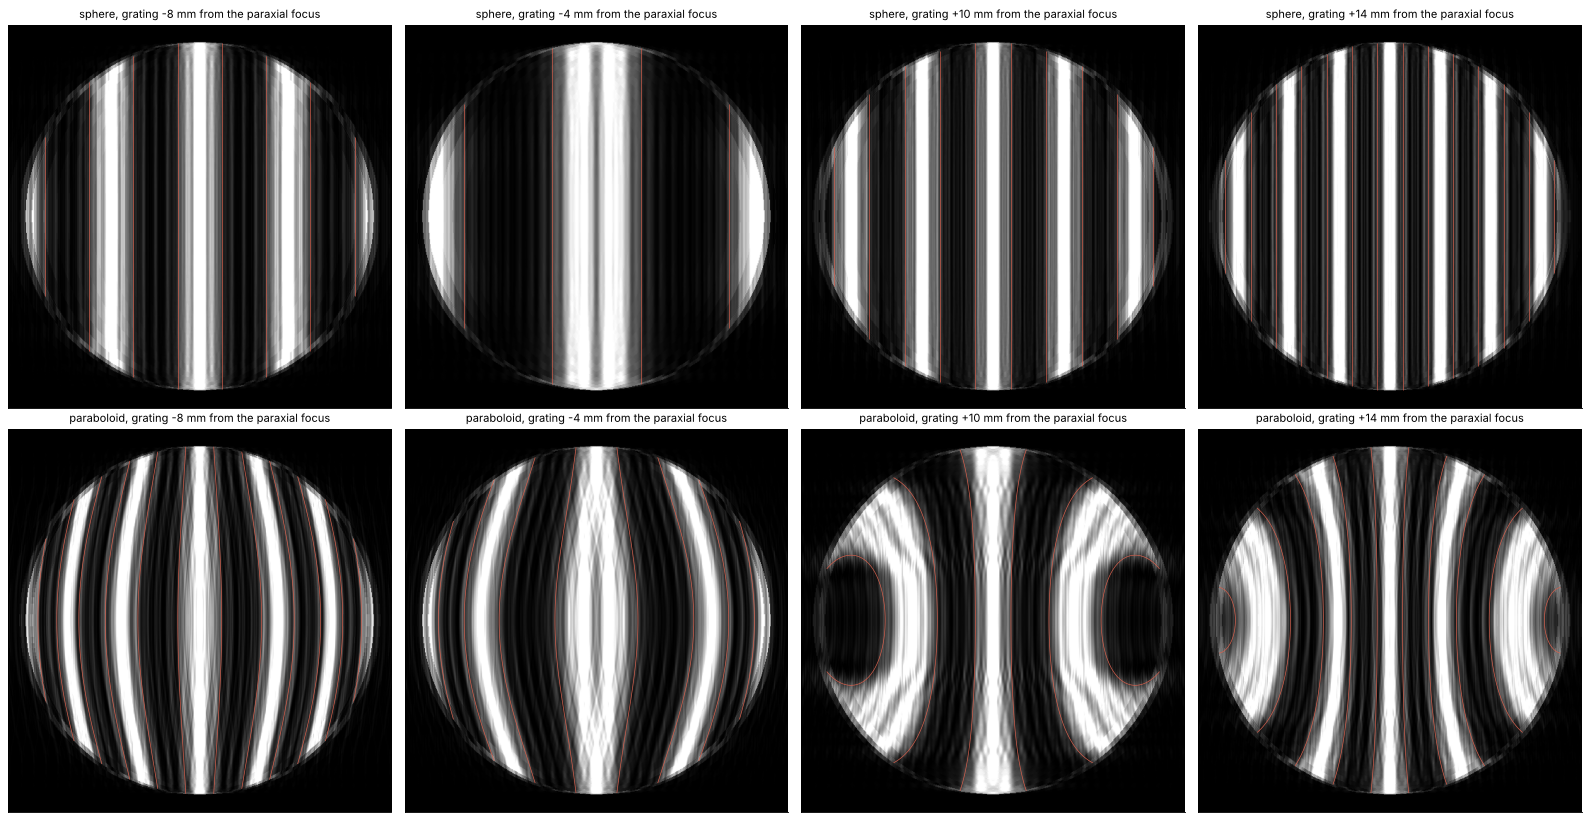

In [9]:
p = 0.254
ronchi = lambda XI, ETA: sch.ronchi_ruling(XI, ETA, p)
W_s = 0.0*X4
deltas = [-8.0, -4.0, 10.0, 14.0]
fig, axes = plt.subplots(2, 4, figsize=(20, 10.4))
for i, (W0, name) in enumerate([(W_s, "sphere"), (W_p, "paraboloid")]):
    for j, d in enumerate(deltas):
        W = (W0 + sch.defocus_wavefront(X4, Y4, R4, d))*A4
        img = np.abs(sch.filtered_image(A4*np.exp(1j*k*W), x4, y4, wl, R4, ronchi))**2
        ax = axes[i, j]
        ax.imshow(img, extent=(x4[0], x4[-1], y4[0], y4[-1]), cmap="gray", vmin=0, vmax=1.2)
        eps_x, _ = sch.transverse_aberration(W0 + sch.defocus_wavefront(X4, Y4, R4, d), x4, y4, R4)
        ph = np.ma.masked_where(A4 == 0, eps_x/p)
        lev = np.arange(np.floor(ph.min()) - 0.25, ph.max() + 1, 0.5)
        ax.contour(X4, Y4, ph, levels=lev, colors=RED, linewidths=0.6, linestyles="solid")
        ax.set_xlim(-0.55*D, 0.55*D); ax.set_ylim(-0.55*D, 0.55*D)
        ax.set_xticks([]); ax.set_yticks([])
        ax.set_title(f"{name}, grating {d:+.0f} mm from the paraxial focus", fontsize=10)
plt.tight_layout()

# the band period of the sphere against p R/|delta|
for d in [-8.0, 10.0, 14.0]:
    W = sch.defocus_wavefront(X4, Y4, R4, d)*A4
    img = np.abs(sch.filtered_image(A4*np.exp(1j*k*W), x4, y4, wl, R4, ronchi))**2
    row = img[N4//2, np.abs(x4) < 0.45*D] - img[N4//2, np.abs(x4) < 0.45*D].mean()
    spec = np.abs(np.fft.rfft(row*np.hanning(len(row)), n=16*len(row)))
    f_peak = np.fft.rfftfreq(16*len(row), x4[1] - x4[0])[np.argmax(spec[5:]) + 5]
    print(f"delta = {d:+.0f} mm: band period {1/f_peak:.2f} mm, p R/|delta| = {p*R4/abs(d):.2f} mm")

The simulated bands follow the geometric contours: the sphere gives straight
bands of the expected period, the paraboloid bands that bow outwards
inside the focus and inwards beyond the marginal focus (4.7 mm), where
the outer bands close into loops: the familiar Ronchigrams that amateur
mirror makers compare with printed templates. The band edges are not sharp: each edge is a knife, and
the coherent point source adds the shearing fringes and diffraction.

## 5. How sensitive is the knife?

Let the wavefront carry a weak ripple $W = w\cos(qx)$ with the period
$\Lambda = 2\pi/q$. It diffracts light into the orders $\pm 1$, which land
at $\xi_1 = \pm\lambda R/\Lambda$ beside the pinhole image. Two regimes:

- **Geometric** (the source image wider than the order distance,
  $a > \xi_1$): the slope $\varepsilon = \partial W/\partial x$ moves the
  source image across the knife, and Toepler's formula
  $\Delta I/I = R\varepsilon/a$ holds; with $\varepsilon = -wq\sin(qx)$
  the contrast amplitude is $Rwq/a = kw\,\xi_1/a$. The knife measures
  slope, and the sensitivity grows as the source shrinks.
- **Diffraction limited** (a small source, $a < \xi_1$): the knife passes
  the zero order and the $+1$ order but blocks the $-1$ order, a single
  sideband filter like half a phase contrast plate. The contrast becomes
  $kw$, the phase of the ripple itself, independent of $\Lambda$. With a
  true point source the knife also halves the zero order, and the contrast
  doubles to $2kw$.

So $\Delta I/I_\mathrm{b} = kw\min(\xi_1/a, 1)$, or $2kw$ for a point
source. The simulation sweeps the ripple period for three source sizes,
$w = \lambda/200$, and fits the contrast amplitude.

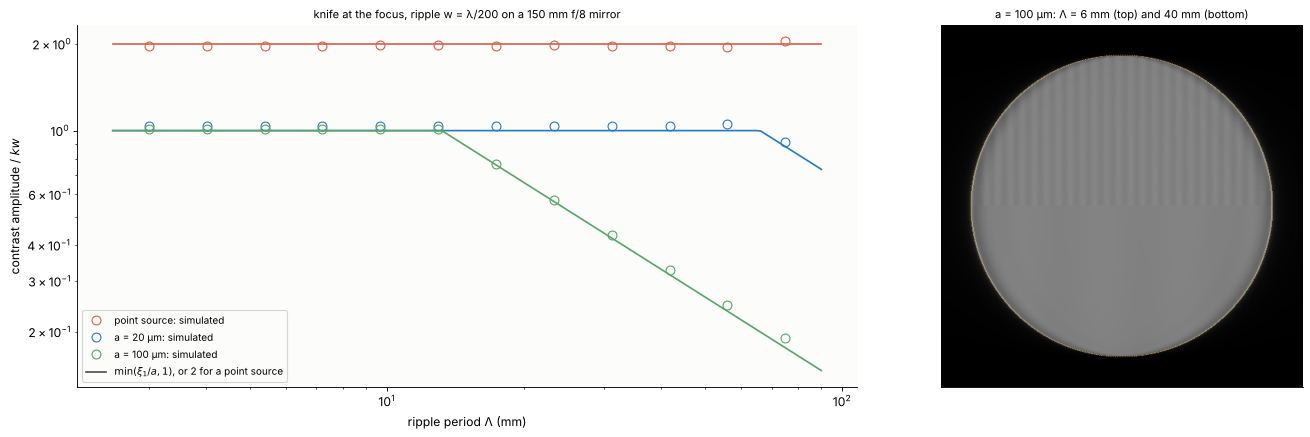

In [10]:
w_r = wl/200
inner = Rho < 0.3*D
periods = np.geomspace(3, 75, 12)
sources = [(0.0, "point source", RED), (0.02, "a = 20 µm", BLUE), (0.1, "a = 100 µm", GREEN)]
fig, axes = plt.subplots(1, 2, figsize=(18, 5.6), gridspec_kw=dict(width_ratios=[1.3, 1]))
ax = axes[0]
P_f = np.geomspace(2.5, 90, 200)
for a_s, name, c in sources:
    amp = []
    for Lam in periods:
        q = 2*np.pi/Lam
        img = foucault(w_r*np.cos(q*X), a=a_s, n_src=61)
        rel = img[inner]/img[inner].mean() - 1
        s_ = np.sin(q*X[inner])
        amp.append(-np.sum(rel*s_)/np.sum(s_*s_))
    amp = np.array(amp)/(k*w_r)
    pred = 2.0*np.ones_like(P_f) if a_s == 0 else np.minimum(wl*R/P_f/a_s, 1.0)
    ax.plot(P_f, pred, color=c, lw=1.5)
    ax.plot(periods, amp, "o", color=c, mfc="none", ms=8, label=f"{name}: simulated")
ax.plot([], [], color="0.3", label=r"$\min(\xi_1/a, 1)$, or 2 for a point source")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("ripple period Λ (mm)"); ax.set_ylabel(r"contrast amplitude / $kw$")
ax.set_title(f"knife at the focus, ripple w = λ/200 on a {D:.0f} mm f/{R/(2*D):.0f} mirror", fontsize=10)
ax.legend(fontsize=9)

# two ripples: one too fine and one too coarse for the 100 µm source
Lams = (6.0, 40.0)
W2 = w_r*(np.cos(2*np.pi*X/Lams[0])*(Y > 0) + np.cos(2*np.pi*X/Lams[1])*(Y <= 0))*A
img = foucault(W2, a=0.1, n_src=61)
mirror_image(img/img[A > 0].mean(), axes[1], "a = 100 µm: Λ = 6 mm (top) and 40 mm (bottom)",
             vmax=2)
plt.tight_layout()

The simulation follows the analytic curves. The left panel is the knife's
transfer function for wavefront ripple. Two practical consequences:

- **The λ/1000 of the opticians.** The eye notices about 2 % contrast in
  a uniform field. With a pinhole source, $2kw = 0.02$ gives
  $w = \lambda/630$ on the wavefront, $\lambda/1250$ on the surface, about
  half a nanometre: the knife-edge test is about as sensitive as an
  interferometer, though it shows slopes and is not quantitative.
- **The schlieren trade-off.** Expressed as a deflection angle, the
  smallest visible slope is $\varepsilon_\mathrm{min} = 0.02\,a/f$,
  for $a = 0.1$ mm and $f = 1$ m about 0.4 arc seconds; but the image
  saturates for $|\varepsilon| > a/f$, 20 arc seconds. A small source
  makes the system sensitive, a large one gives it range. Gradients along
  the knife ($\partial W/\partial y$ for a vertical knife) are invisible;
  schlieren photographers turn the knife to choose the direction.

## 6. Schlieren and shadowgraph of a candle plume

Toepler's system makes a parallel beam with a first lens (or mirror) of
focal length $f_1$ from a slit source, sends it through the test section,
and forms an image of the slit on a knife edge with a second lens of focal
length $f_2$; a camera behind the knife images the test section. Without
the knife and with a screen a distance $L$ behind the test section, the
same beam gives a **shadowgraph**: deflected rays pile up or spread out,
and the screen shows the second derivative of the optical path.

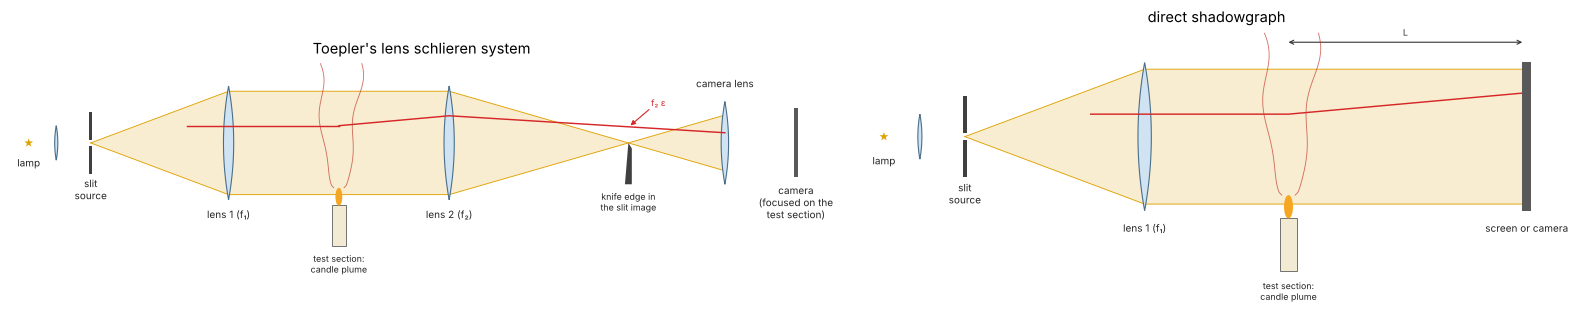

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(20, 4.8), gridspec_kw=dict(width_ratios=[1.15, 1]))
sketch.schlieren_system(axes[0], title="Toepler's lens schlieren system")
sketch.schlieren_system(axes[1], method="shadowgraph", title="direct shadowgraph")
plt.tight_layout()

The test object is the hot plume above a candle flame, rising through a
schlieren field of 58 mm diameter (a soft-edged circular aperture). Its
temperature field is modelled as a laminar, axisymmetric plume,
$\Delta T = \Delta T_0\, s_0/s\; e^{-r^2/b^2}$ with the width
$b = b_0\sqrt{s/s_0}$ growing with the height $s$ above a virtual origin
just above the flame tip ($\Delta T_0 = 600$ K there, 330 K at the bottom
of the field), with a slow sinuous meander that grows with height. The
refractive index follows from the Gladstone–Dale relation
$n - 1 = K\rho$ with the ideal gas density (`air_index()`): hot air has a
lower index, at the bottom of the plume by $1.4\times 10^{-4}$.

The light crosses the plume along $z$. The field after the test section
comes from the WPM (`wpm.wpm_propagate()`) in 1 mm slices from
$z = -24$ to 24 mm, propagated back to the mid plane $z = 0$ on which the
camera is focused. The fast WPM ("levels" method) needs a limited number
of distinct index values per slice; the index is rounded to steps of
$10^{-7}$ (up to some 1500 levels per slice). The check is the straight
line projection $W(x, y) = \int (n - n_\mathrm{air})\,dz$, which ignores
the bending of the rays inside the plume.

WPM through 48 slices: 44 s


optical path through the plume: down to -933 nm (-1.70 waves); WPM minus projection within ±20 mm: 0.20 nm rms, 0.9 nm max
largest deflection: 247 µrad across, 40 µrad along the plume (51 arc seconds)


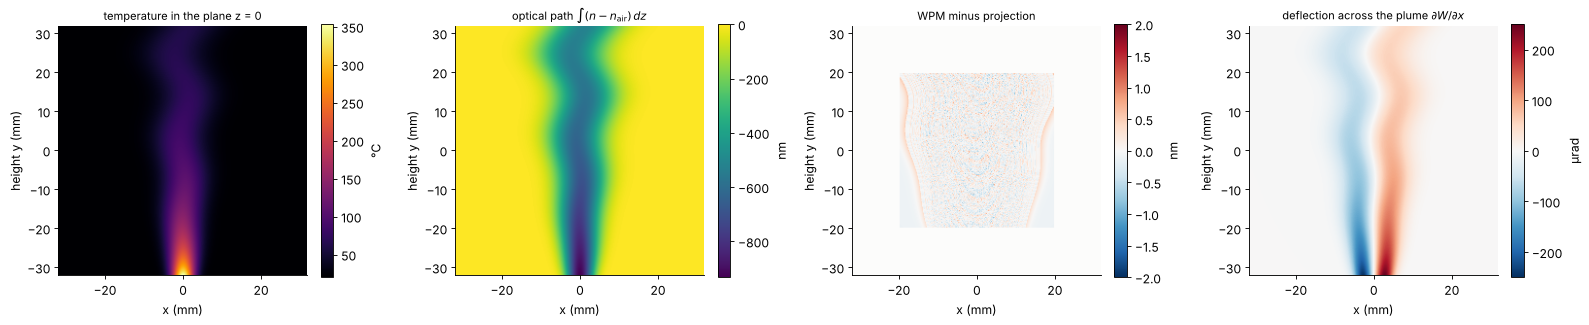

In [12]:
Np, Lp = 256, 64.0
xp_, yp_, Xp, Yp = grid2d(-Lp/2, Lp/2, -Lp/2, Lp/2, Np)
T_air = 293.0
y_src, s0, dT0, b0 = -36.0, 5.0, 600.0, 2.2
n_air = sch.air_index(T_air)


def T_plume(X_, Y_, Z_):
    s = np.clip(Y_ - y_src, 0, None) + s0
    b = b0*np.sqrt(s/s0)
    meander = 2.4*((Y_ - y_src)/Lp)**2*np.sin(2*np.pi*(Y_ - y_src)/22.0)
    return T_air + dT0*(s0/s)*np.exp(-((X_ - meander)**2 + Z_**2)/b**2)


step = 1e-7


def n_quantized(X_, Y_, z):
    dn = sch.air_index(T_plume(X_, Y_, z)) - n_air
    return n_air + np.round(dn/step)*step


aperture = np.exp(-0.5*(np.hypot(Xp, Yp)/29.0)**40)      # the field of view
z_sl = np.arange(-24.0, 24.01, 1.0)
t0 = time.time()
u = aperture.astype(complex)
for z1, z2 in zip(z_sl[:-1], z_sl[1:]):
    u = wpm_propagate(n_quantized, u, xp_, yp_, z1, z2 - z1, wl, method="levels")
u_mid = rayleigh_sommerfeld_I_TF(u, xp_, yp_, -z_sl[-1], wl, n=n_air)[0]
u_mid *= np.exp(-1j*k*n_air*(0.0 - z_sl[0]))           # remove the ambient phase
print(f"WPM through {len(z_sl) - 1} slices: {time.time() - t0:.0f} s")

zz = np.linspace(-40, 40, 801)
W_proj = sum(sch.air_index(T_plume(Xp, Yp, z)) - n_air for z in zz)*(zz[1] - zz[0])
fov = np.hypot(Xp, Yp) < 25
sq = np.ix_(np.abs(yp_) < 20, np.abs(xp_) < 20)            # unwrap the phase inside the field
phase = np.unwrap(np.unwrap(np.angle(u_mid[sq]), axis=0), axis=1)
dW = np.full((Np, Np), np.nan)
dW[sq] = phase/k - W_proj[sq]
dW -= np.nanmean(dW)
eps_x, eps_y = sch.transverse_aberration(W_proj, xp_, yp_, 1.0)
print(f"optical path through the plume: down to {W_proj.min()*1e6:.0f} nm ({W_proj.min()/wl:.2f} waves); "
      f"WPM minus projection within ±20 mm: {np.nanstd(dW)*1e6:.2f} nm rms, "
      f"{np.nanmax(np.abs(dW))*1e6:.1f} nm max")
print(f"largest deflection: {np.abs(eps_x).max()*1e6:.0f} µrad across, {np.abs(eps_y).max()*1e6:.0f} µrad "
      f"along the plume ({np.abs(eps_x).max()*180/np.pi*3600:.0f} arc seconds)")

ext_p = (xp_[0], xp_[-1], yp_[0], yp_[-1])
fig, axes = plt.subplots(1, 4, figsize=(20, 5))
im = axes[0].imshow(T_plume(Xp, Yp, 0.0) - 273.15, extent=ext_p, cmap="inferno")
plt.colorbar(im, ax=axes[0], fraction=0.046, label="°C")
axes[0].set_title("temperature in the plane z = 0", fontsize=10)
im = axes[1].imshow(W_proj*1e6, extent=ext_p, cmap="viridis")
plt.colorbar(im, ax=axes[1], fraction=0.046, label="nm")
axes[1].set_title(r"optical path $\int(n - n_\mathrm{air})\,dz$", fontsize=10)
im = axes[2].imshow(dW*1e6, extent=ext_p, cmap="RdBu_r", vmin=-2, vmax=2)
plt.colorbar(im, ax=axes[2], fraction=0.046, label="nm")
axes[2].set_title("WPM minus projection", fontsize=10)
im = axes[3].imshow(eps_x*1e6, extent=ext_p, cmap="RdBu_r", vmin=-250, vmax=250)
plt.colorbar(im, ax=axes[3], fraction=0.046, label="µrad")
axes[3].set_title(r"deflection across the plume $\partial W/\partial x$", fontsize=10)
for ax in axes:
    ax.set_xlabel("x (mm)"); ax.set_ylabel("height y (mm)")
plt.tight_layout()

The plume is a phase object of about a wave and a half, and it bends the
light by up to some 50 arc seconds. The WPM and the projection agree to
about a nanometre: over 48 mm the rays move sideways by only a few µm, so
the projection (the thin object picture) is good, and the WPM shows how
far. The schlieren system has $f_2 = 1$ m. In the focal plane the light
of the plume spreads over $f_2\varepsilon \approx \pm 0.25$ mm around the
slit image; the slit source has the half width $a$ in the knife plane, and
`extended_source_image()` adds the images of 41 source points. A vertical
knife shows $\partial W/\partial x$, a horizontal one
$\partial W/\partial y$ (and hardly anything of this plume), and a large
source keeps the image linear where a small one saturates.

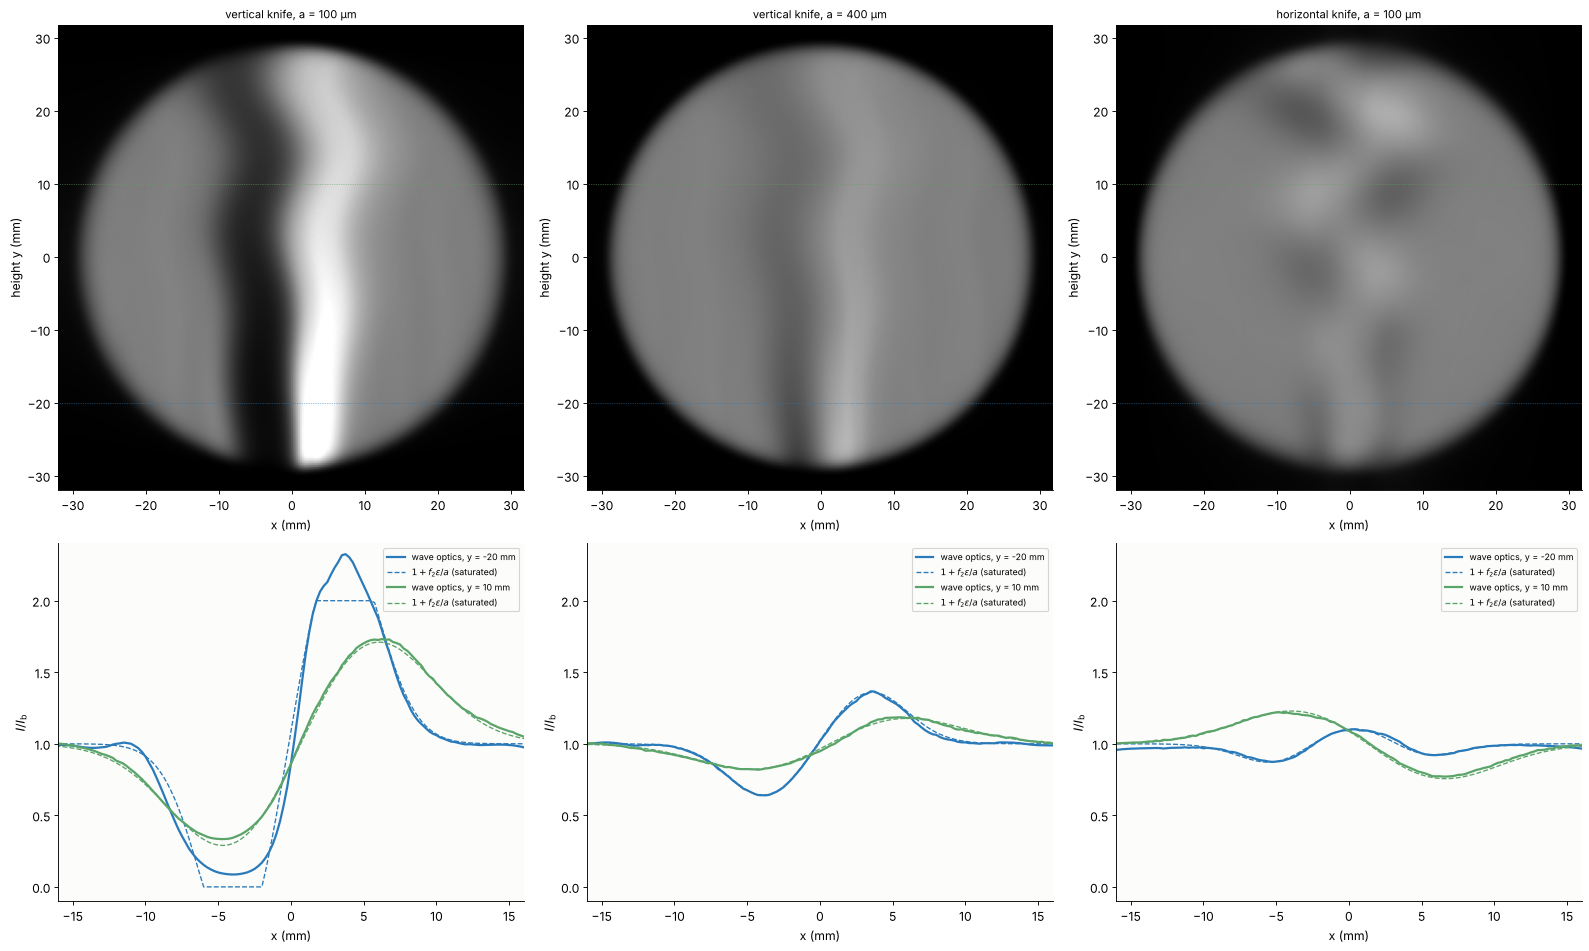

In [13]:
f2 = 1000.0
field_p = u_mid
tests = [(0.1, 0.0, "vertical knife, a = 100 µm"), (0.4, 0.0, "vertical knife, a = 400 µm"),
         (0.1, np.pi/2, "horizontal knife, a = 100 µm")]
fig, axes = plt.subplots(2, 3, figsize=(20, 12), gridspec_kw=dict(height_ratios=[1.35, 1]))
for j, (a_s, ang, name) in enumerate(tests):
    m = lambda XI, ETA, ang=ang: sch.knife_edge(XI, ETA, angle=ang)
    offs = np.linspace(-a_s, a_s, 41)
    offs2 = np.c_[offs*np.cos(ang), offs*np.sin(ang)]
    img = sch.extended_source_image(field_p, xp_, yp_, wl, f2, m, offs2)
    img /= np.median(img[fov & (np.abs(Xp) > 15)])
    axes[0, j].imshow(img, extent=ext_p, cmap="gray", vmin=0, vmax=2)
    axes[0, j].set_title(name, fontsize=10)
    axes[0, j].set_xlabel("x (mm)"); axes[0, j].set_ylabel("height y (mm)")
    eps_n = eps_x*np.cos(ang) + eps_y*np.sin(ang)
    lin = 1 + sch.knife_edge_contrast(eps_n, f2, a_s)
    ax = axes[1, j]
    for yr, c in [(-20.0, BLUE), (10.0, GREEN)]:
        r_ = np.argmin(np.abs(yp_ - yr))
        ax.plot(xp_, img[r_], color=c, lw=2, label=f"wave optics, y = {yr:.0f} mm")
        ax.plot(xp_, lin[r_], "--", color=c, lw=1.2, label=r"$1 + f_2\varepsilon/a$ (saturated)")
        axes[0, j].axhline(yr, color=c, lw=0.6, ls=":")
    ax.set_xlim(-16, 16); ax.set_ylim(-0.1, 2.4)
    ax.set_xlabel("x (mm)"); ax.set_ylabel(r"$I/I_\mathrm{b}$"); ax.legend(fontsize=8, loc="upper right")
plt.tight_layout()

With the 100 µm source the plume saturates near its base: one flank goes
black, the other white, the hallmark of a schlieren system that is too
sensitive for its object. The 400 µm source keeps the whole plume in the
linear range and follows Toepler's formula; the horizontal knife sees only
the weak vertical gradients and the meander. Real schlieren systems use
the same trade-off, and colour schlieren replaces the knife by a graded
or coloured filter to code the direction and size of the deflection.

The **shadowgraph** needs no focus at all. A screen at the distance $L$
behind the test section receives each ray displaced by $L\varepsilon$; to
first order the brightness changes by
$\Delta I/I = -L\nabla^2 W$ (`shadowgraph_contrast()`, the transport of
intensity equation of notebook [29](29_TIE.ipynb)), so the shadowgraph
shows the second derivative of the optical path: a hot plume (a negative
lens, $W < 0$ in the core) spreads the light from its core into bright
caustic edges. The WPM field propagated by $L$ with the angular spectrum
method, against the linear formula:

L = 1 m: rms deviation from 1 - L laplace(W) 0.003, contrast range 0.97 to 1.02
L = 3 m: rms deviation from 1 - L laplace(W) 0.004, contrast range 0.91 to 1.06
L = 10 m: rms deviation from 1 - L laplace(W) 0.037, contrast range 0.77 to 1.19
L = 20 m: rms deviation from 1 - L laplace(W) 0.136, contrast range 0.63 to 1.45


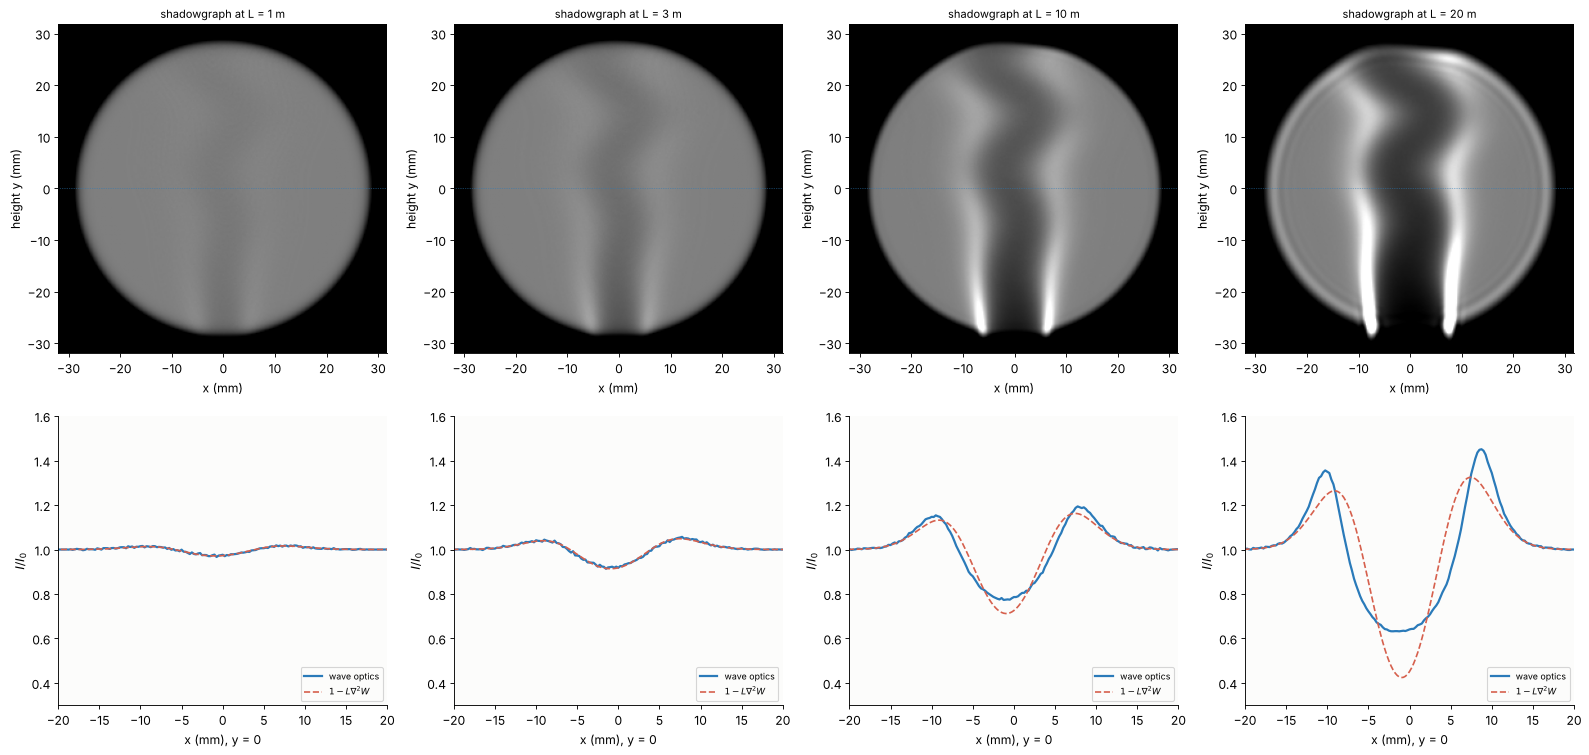

In [14]:
Ls = [1000.0, 3000.0, 10000.0, 20000.0]
fig, axes = plt.subplots(2, 4, figsize=(20, 9.6), gridspec_kw=dict(height_ratios=[1.25, 1]))
for j, Ld in enumerate(Ls):
    u_L = rayleigh_sommerfeld_I_TF(field_p, xp_, yp_, Ld, wl, n=n_air)[0]
    I_L = np.abs(u_L)**2
    axes[0, j].imshow(I_L, extent=ext_p, cmap="gray", vmin=0.4, vmax=1.6)
    axes[0, j].set_title(f"shadowgraph at L = {Ld/1000:g} m", fontsize=10)
    axes[0, j].set_xlabel("x (mm)"); axes[0, j].set_ylabel("height y (mm)")
    lin = 1 + sch.shadowgraph_contrast(W_proj, xp_, yp_, Ld)
    ax = axes[1, j]
    r_ = np.argmin(np.abs(yp_ - 0.0))
    ax.plot(xp_, I_L[r_], color=BLUE, lw=2, label="wave optics")
    ax.plot(xp_, lin[r_], "--", color=RED, lw=1.5, label=r"$1 - L\nabla^2 W$")
    axes[0, j].axhline(0.0, color=BLUE, lw=0.6, ls=":")
    ax.set_xlim(-20, 20); ax.set_xlabel("x (mm), y = 0"); ax.set_ylabel(r"$I/I_0$")
    ax.legend(fontsize=8, loc="lower right"); ax.set_ylim(0.3, 1.6)
    core = np.abs(xp_) < 15
    print(f"L = {Ld/1000:g} m: rms deviation from 1 - L laplace(W) {np.std(I_L[r_, core] - lin[r_, core]):.3f}, "
          f"contrast range {I_L[r_, core].min():.2f} to {I_L[r_, core].max():.2f}")
plt.tight_layout()

At 1 m the shadowgraph of this plume is faint, a few per cent, and
follows the linear formula; at 3 m it is still close. At 10 and 20 m the
rays from the hot core have moved by millimetres, the light piles up in
bright edges and the dark core no longer follows $1 - L\nabla^2 W$,
which the rays cross on their way to forming caustics. (The edge of the
field blurs with the distance too.) A shadowgraph of a candle plume in
sunlight on a wall a few metres away shows exactly these bright edges. The shadowgraph needs no knife, works with
a large source and large objects, and is the method of choice for strong
gradients (shock waves, flames); the schlieren system is more sensitive to
weak ones.

## Summary

| Method | Filter in the focus | Image shows | Sensitivity, range |
|---|---|---|---|
| Foucault test, schlieren | knife edge | slope across the edge, $\Delta I/I = f\varepsilon/a$ | $\varepsilon_\mathrm{min} \approx 0.02\,a/f$; saturates at $a/f$; point source: phase $2kw$ for fine ripple |
| wire test, dark field schlieren | opaque wire or stop | $\lvert$slope$\rvert$ near zero dark, zones in focus | both signs at once |
| slit | narrow slit | zones in focus bright | selects one slope |
| Ronchi test | coarse grating | contours of the transverse aberration every $p$ | fringe density $\propto \delta/p$; also a shearing interferometer ($\lambda R/p$) |
| shadowgraph | none (screen at $L$) | $\Delta I/I = -L\nabla^2 W$ | needs strong gradients; caustics at large $L$ |

Notebook [25](25_shack_hartmann_vs_phase_diversity.ipynb) measures
wavefronts quantitatively with lenslets and through-focus images,
[23](23_interferometry.ipynb) and [24](24_radius_interferometer.ipynb)
with interferometers, [29](29_TIE.ipynb) from defocused intensities like a
shadowgraph, and [53](53_phase_contrast_dic.ipynb) makes phase visible in
the microscope with Zernike's phase plate, the symmetric cousin of the
knife edge.

In [15]:
print(f"run time {time.time() - t_start:.0f} s")

run time 82 s


## References

- L. Foucault, "Mémoire sur la construction des télescopes en verre argenté", Ann. Obs. Imp. Paris 5, 197-237 (1859).
- A. Toepler, *Beobachtungen nach einer neuen optischen Methode*, Max Cohen und Sohn, Bonn (1864).
- V. Ronchi, "Forty years of history of a grating interferometer", Appl. Opt. 3, 437-451 (1964).
- A. Couder, "Recherches sur les déformations des grands miroirs employés aux observations astronomiques", Bull. Astron. 7, 201-281 (1932).
- J. Texereau, *How to Make a Telescope*, 2nd ed., Willmann-Bell (1984).
- D. Malacara (ed.), *Optical Shop Testing*, 3rd ed., Wiley (2007), chapters 8 (Foucault, wire and Ronchi tests) and 9 (Ronchi test).
- E. H. Linfoot, *Recent Advances in Optics*, Clarendon Press (1955), chapter 2 (the diffraction theory of the Foucault test).
- G. S. Settles, *Schlieren and Shadowgraph Techniques*, Springer (2001).
- W. Merzkirch, *Flow Visualization*, 2nd ed., Academic Press (1987).
- K.-H. Brenner and W. Singer, "Light propagation through microlenses: a new simulation method", Appl. Opt. 32, 4984-4988 (1993).